# Noisy Simulation, Decoding & Confidence Filtering

<div style="border-left:4px solid #6d3f8c;background:#6d3f8c1a;border-radius:4px;margin:1em 0;"><div style="background:#6d3f8c;color:#ffffff;padding:0.35em 0.8em;font-weight:600;"><span style="display:inline-block;width:1.15em;height:1.15em;line-height:1.15em;border-radius:50%;background:#ffffff;color:#6d3f8c;text-align:center;font-weight:700;margin-right:0.5em;">!</span>Chapter focus</div>

<div style="padding:0.1em 1em;">

How do you run circuit-level Monte Carlo sweeps and use soft-output decoder score filtering (`max_readout_score`) to achieve $O(p^2)$ logical error suppression?

</div>

</div>

## Learning objectives

After completing this unit, you will be able to:

- Configure `NoiseConfig` and run parallel Monte Carlo sweeps (`sample_sweep`, `plot_sweep`) across physical error probabilities.
- Compare preparation-flag-only post-selection (`max_readout_score=None`) against syndrome/readout-score post-selection (`max_readout_score=0.05`).
- Contrast $d=2$ post-selected error detection on $C_4$ with active $d=3$ error correction (`max_readout_score=None`) on the $[[7, 1, 3]]$ Steane code.

## Before you begin

This course requires `qdk[ec]>=1.33.0`, `qodec>=0.2.0`, `paulimer`, `binar`, and `ipykernel`. Run the cell below to verify your active Python kernel and environment.

In [ ]:
# If packages are missing, first select a dedicated Python environment/kernel,
# then uncomment the next line and run this cell again.
# %pip install -r ../requirements.txt

from _unit import check_env

check_env()

## Configuring Physical Gate Noise & The `mresetz` Sharp Edge

When running circuit-level Monte Carlo simulations with `qdk.simulation.run_qir`, physical noise is configured via **`NoiseConfig`** on the simulator's primitive operations (`h`, `x`, `y`, `z`, `cx`, `mresetz`):
```python
noise = NoiseConfig()
for gate in ["h", "x", "y", "z", "cx"]:
    getattr(noise, gate).set_depolarizing(p)
noise.mresetz.x = p
```
> ⚠️ **Sharp Edge (`M` vs. `mresetz`):** In the current QDK simulator, Stim's `M` instruction maps to `mresetz`, where `noise.mresetz.x = p` applies an $X$ bit-flip error **after** the measurement outcome bit is recorded (affecting the post-measurement reset state rather than flipping the recorded classical bit). In `syndrome`, `prepare_z_all`, `prepare_x_all`, `measure_z_all`, and `measure_x_all`, every gate leading *into* the measurement (`H`, `CX`) is still subject to full depolarizing noise `p`, which flips the measurement outcomes as expected.

## Why Preparation Flags Alone Leave O(p) Logical Errors on `syndrome`

In Module 6, we upgraded all 6 gadgets of $C_4$ to **circuit distance 2**:
- In `prepare_z_all` and `prepare_x_all`, any single fault that corrupts 2 data qubits raises the `reject` flag (`M 4 == 1`), so discarding flagged shots suppresses SPAM logical errors from $O(p)$ to **$O(p^2)$**!
- **What about `syndrome Z` and `syndrome X`?**
  Recall from Module 6 Cell 1 what happens when a single problematic fault (`Z_5` after call 5, or `X_4` after call 7) occurs inside `syndrome`:
  - It flips **one syndrome check** (`checks: [0]` or `checks: [1]`).
  - It leaves a **weight-2 logical error** (`X_0 X_1` or `Z_0 Z_1`) on the data qubits.
  - Because $C_4$ is a **distance-2 error-detecting code**, any single data error *also* flips that exact same syndrome check!
  - Therefore, if a decoder tries to *correct* a non-zero syndrome check instead of rejecting the shot, it cannot distinguish a weight-1 data fault from a weight-2 problematic fault—and whenever a problematic fault occurs (with probability $O(p)$), the decoder's "correction" leaves a logical error!

## Restoring O(p^2) Fault Tolerance with Decoder Confidence Post-Selection (`max_readout_score`)

How do we turn a soft-output decoder (like **`deq`**'s `black-box-relay-bp` decoder with `forced_gap=True`, or QDK's syndrome margin decoder) into a fault-tolerant post-selected decoder for $C_4$?
- For each decoded shot, the decoder computes a **readout score** $\in [0, 1]$ measuring syndrome ambiguity / correction weight.
- When all syndrome checks are satisfied (zero syndrome), the readout score is `0.0`.
- When a single fault inside `syndrome` triggers a parity check, the readout score jumps above **`max_readout_score = 0.05`**, causing the decoder to mark the shot as failed (`on_shot_failure="discard"`).
- Under the hood in `_walkthrough_simulation.py`, `prepare_deq_decoder` is configured as:
  ```python
  from functools import partial
  from deq.runtime import Runtime
  from qdk.simulation.decoders import prepare_deq_decoder

  decoder = partial(
      prepare_deq_decoder,
      runtime_factory=lambda seed: Runtime(
          decoder="black-box-relay-bp",
          decoder_config={"parallel": 1, "seed": seed},
          coordinator="monolithic",
          coordinator_config={"forced_gap": True},  # Compute soft readout gap score
          controller="jit",                         # Compile check & error models JIT
      ),
      max_readout_score=0.05,                       # Reject ambiguous non-zero syndromes
  )
  ```
- As a result, **both** preparation flag failures *and* single-fault syndrome detections are post-selected out, pushing the logical error rate of `syndrome Z` and `syndrome X` well **below the physical error rate $p$** with quadratic $O(p^2)$ scaling!

[Flags only @ p=0.01] SPAM Z       : LER = 0.0369, rejection = 5.25%
[Flags only @ p=0.01] SPAM X       : LER = 0.0897, rejection = 5.25%
[Flags only @ p=0.01] syndrome Z   : LER = 0.0803, rejection = 3.50%
[Flags only @ p=0.01] syndrome X   : LER = 0.0848, rejection = 2.75%


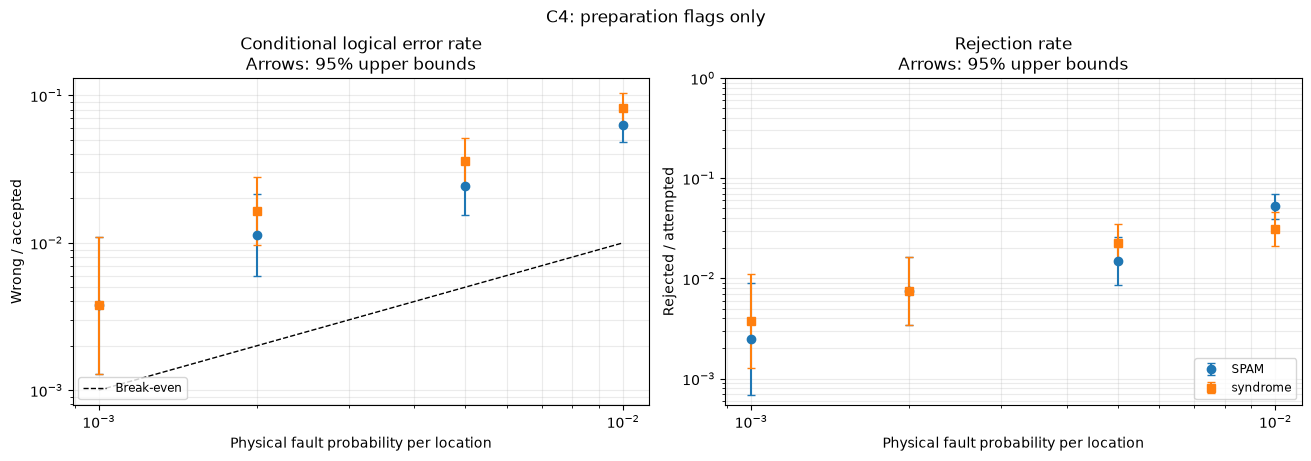

In [2]:
import qodec
import qdk.ec as ec
from _unit import simulation

# Sweep 1 — Preparation Flags Only (`max_readout_score=None`)
from _unit import simulation
simulation.ensure_course_state(globals(), stage="upgraded_all")

noise_rates = [1e-3, 2e-3, 5e-3, 1e-2]

sweep_flags_only = simulation.sample_sweep(
    protocol,
    benchmarks,
    noise_rates,
    shots=400,
    workers=4,
    max_readout_score=None,
)

for name, pts in sweep_flags_only.items():
    p_hi, counts_hi = pts[-1]
    ler_hi = counts_hi["wrong"] / counts_hi["accepted"]
    rej_hi = 1.0 - (counts_hi["accepted"] / counts_hi["attempted"])
    print(f"[Flags only @ p={p_hi:g}] {name:<12} : LER = {ler_hi:.4f}, rejection = {rej_hi:.2%}")

simulation.plot_sweep(sweep_flags_only, title="C4: preparation flags only")

[Readout score <= 0.05 @ p=0.01] SPAM Z       : LER = 0.0000, rejection = 9.50%
[Readout score <= 0.05 @ p=0.01] SPAM X       : LER = 0.0078, rejection = 14.67%
[Readout score <= 0.05 @ p=0.01] syndrome Z   : LER = 0.0019, rejection = 14.50%
[Readout score <= 0.05 @ p=0.01] syndrome X   : LER = 0.0000, rejection = 18.33%


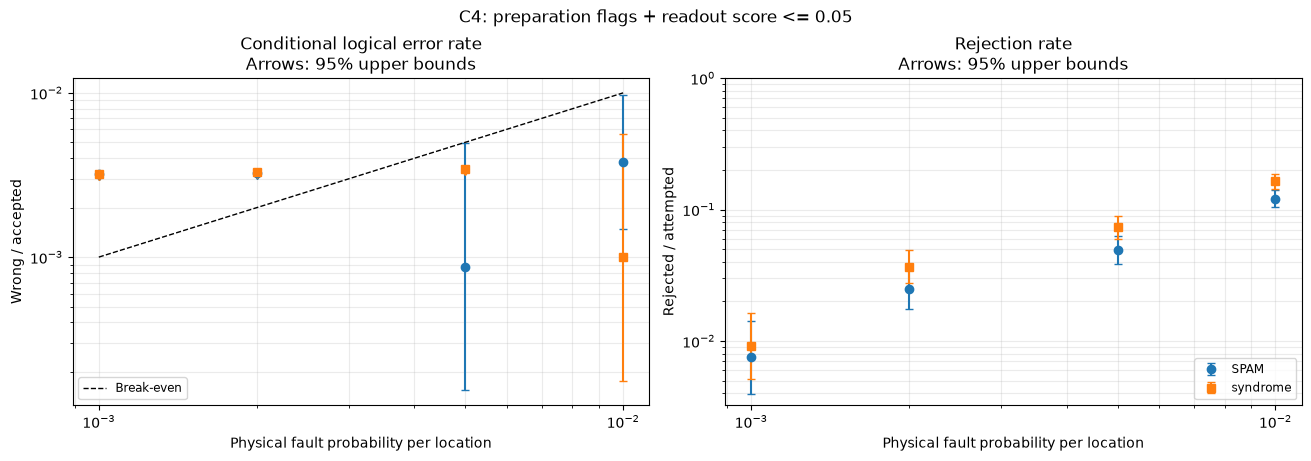

In [3]:
# Sweep 2 — Preparation Flags + Decoder Readout Score Filtering (`max_readout_score=0.05`)
from _unit import simulation
simulation.ensure_course_state(globals(), stage="upgraded_all")

sweep_postselected = simulation.sample_sweep(
    protocol,
    benchmarks,
    noise_rates,
    shots=600,
    workers=4,
    max_readout_score=0.05,
)

for name, pts in sweep_postselected.items():
    p_hi, counts_hi = pts[-1]
    ler_hi = counts_hi["wrong"] / counts_hi["accepted"]
    rej_hi = 1.0 - (counts_hi["accepted"] / counts_hi["attempted"])
    print(f"[Readout score <= 0.05 @ p={p_hi:g}] {name:<12} : LER = {ler_hi:.4f}, rejection = {rej_hi:.2%}")

simulation.plot_sweep(sweep_postselected, title="C4: preparation flags + readout score <= 0.05")

## Bridging d=2 Error Detection (C4) to d=3 Active Error Correction (`[[7, 1, 3]]` Steane Code with `deq`)

Up to this point, we have focused on $C_4$ ($[[4, 2, 2]]$), where $d = 2$ means single faults in `syndrome` can only be **detected** and post-selected via `max_readout_score=0.05`.
What happens when we move to a **distance-3 error-correcting code** such as the **$[[7, 1, 3]]$ Steane code** (`Steane_7_1_3`)?

With $t = \lfloor (3 - 1) / 2 \rfloor = 1$, a distance-3 code can **actively correct** any single fault without rejecting non-zero syndromes (`max_readout_score=None`, **0% syndrome rejection**)—*provided* we design its gadgets so that no single fault spreads to an unflagged weight-2 data error:
1. **Inspecting `bare-css/v1` on Steane (`d_circuit = 3` Readout, `d_circuit = 2` Unflagged Syndrome, `d_circuit = 1` Prep):**
   - `measure_z_all` already has **`d_circuit = 3`** (it takes 3 independent bit-flip faults to flip $\bar{Z}$ without flipping any of the three weight-4 $Z$ parity checks).
   - `syndrome` in `bare-css/v1` has **`d_circuit = 2`** (`witness: X_7 after call 2; X_8 after call 10`): a single problematic fault `X_7` on an $X$-stabilizer ancilla spreads to two data qubits (`X_4 X_6`), which only needs one more fault (`X_8`) to form a weight-3 logical error. However, because `bare-css/v1` extracts the $X$ stabilizers (`7..9`) *before* the $Z$ stabilizers (`10..12`), any $X$ problematic fault on `7..9` is immediately measured by the subsequent $Z$ checks (`10..12`), while any $Z$ problematic fault on `10..12` commutes with final $Z$-basis readout!
2. **Upgrading `prepare_z_all` from $d_{\text{circuit}} = 1$ to $d_{\text{circuit}} = 3$ with a 9-CNOT Fan-Out + Single Flag Ancilla (`M 7`):**
   - `bare-css/v1` initializes $|0\rangle_L$ by measuring the three $X$ stabilizers, which has $d_{\text{circuit}} = 1$.
   - Instead, we prepare the 3 independent $X$-stabilizer generators unitarily by placing qubits `{0, 1, 3}` in $|+\rangle$ (`H 0 1 3`) and fanning out 9 CNOTs so that **only `{0, 1, 3}` ever act as CNOT controls** (`CX 0 6, CX 1 6, CX 3 6`, `CX 0 2, CX 1 2, CX 3 5`, `CX 0 4, CX 1 5, CX 3 4`), while `{2, 4, 5, 6}` are strictly CNOT targets.
   - Because `{2, 4, 5, 6}` are never CNOT controls, any single initialization or gate fault on `{2, 4, 5, 6}` remains weight-1! Only an $X$ fault on control qubits `{0, 1, 3}` during the fan-out can spread to weight 2—and we catch every such fault with 3 CNOTs into a single **flag ancilla** on qubit `7` (`CX 2 7, CX 4 7, CX 5 7, M 7` checking $Z_2 Z_4 Z_5$).
   - As `ec.GadgetProfile` confirms below, this flagged unitary encoder achieves exact **`d_circuit = 3`**, and `prepare_deq_decoder` (`black-box-relay-bp`) achieves quadratic **$O(p^2)$ active error correction** well below physical $p$ with **`max_readout_score=None` (0% syndrome rejection / 100% syndrome acceptance)**!

In [4]:
# Active d=3 Error Correction on the [[7, 1, 3]] Steane Code (with `deq` & `max_readout_score=None`)
from _unit import simulation
import qodec
from qdk import TargetProfile, ec, qsharp

# 1. Define the [[7, 1, 3]] Steane code and synthesize its baseline protocol
steane = qodec.Code(
    "Steane_7_1_3",
    stabilizers=[
        "X_0 X_2 X_4 X_6", "X_1 X_2 X_5 X_6", "X_3 X_4 X_5 X_6",
        "Z_0 Z_2 Z_4 Z_6", "Z_1 Z_2 Z_5 Z_6", "Z_3 Z_4 Z_5 Z_6",
    ],
    x=["X_0 X_1 X_2 X_3 X_4 X_5 X_6"],
    z=["Z_0 Z_1 Z_2 Z_3 Z_4 Z_5 Z_6"],
)
steane_proto = ec.build_qodec(steane, strategy="bare-css/v1", strict=False)
sg = steane_proto.layers[0].gadgets

# 2. Upgrade `prepare_z_all` to exact circuit distance d_circuit = 3 using 9 fan-out CNOTs + 1 flag ancilla (qubit 7)
prep_z = sg["prepare_z_all"]
prep_z.implements.flags = ["reject"]
prep_z.circuit.source = """R 0 1 2 3 4 5 6 7
H 0 1 3
CX 0 6
CX 1 6
CX 3 6
CX 0 2
CX 1 2
CX 3 5
CX 0 4
CX 1 5
CX 3 4
CX 2 7
CX 4 7
CX 5 7
M 7
"""
prep_z.readouts = [{"reject": ["circuit.readouts[0]"]}]
prep_z.checks = []
sg["prepare_z_all"] = ec.filled(prep_z)

print("=== Steane [[7, 1, 3]] Gadget Circuit Distances ===")
expected_d = {"prepare_z_all": 3, "syndrome": 2, "measure_z_all": 3}
for gname, exp_val in expected_d.items():
    d = ec.GadgetProfile(sg[gname]).distance()
    print(f"  {gname:<16} : d_circuit = {d.value} (witness: {d.witness})")
    assert d.value == exp_val, f"Expected d_circuit = {exp_val} for {gname}, got {d.value}"

# 3. Compile `SteaneSyndromeZ` and run active error correction (`max_readout_score=None` -> 0% syndrome rejection!)
qsharp.init(target_profile=TargetProfile.Adaptive_RI)
qsharp.eval("""
@Measurement()
operation prepare_z_all(block : Qubit) : Result { body intrinsic; }
@Measurement()
operation measure_z_all(block : Qubit) : Result { body intrinsic; }
operation syndrome(block : Qubit) : Unit { body intrinsic; }

operation SteaneSyndromeZ() : (Result[], Result[]) {
    use block = Qubit();
    let reject = prepare_z_all(block);
    syndrome(block);
    let z = measure_z_all(block);
    ([reject], [z])
}
""")
steane_qir = {"Steane Syndrome Z": str(qsharp.compile("SteaneSyndromeZ()"))}

# Run with `deq` (`black-box-relay-bp`) and `max_readout_score=None` (every syndrome is actively corrected, never discarded!)
steane_sweep = simulation.sample_sweep(
    steane_proto,
    steane_qir,
    [1e-3, 2e-3, 5e-3],
    shots=400,
    workers=4,
    max_readout_score=None,
)

print("\n=== Steane [[7, 1, 3]] Active Error Correction (`deq` Relay-BP, max_readout_score=None) ===")
print(f"{'Physical p':<12} | {'Active-EC Logical Error Rate':<30} | {'Prep-Flag Acceptance'}")
print("-" * 72)
for p_val, counts in steane_sweep["Steane Syndrome Z"]:
    ler = counts["wrong"] / counts["accepted"]
    acc = counts["accepted"] / counts["attempted"]
    print(f"{p_val:<12.4f} | {ler:<30.5f} | {acc:.1%}")

=== Steane [[7, 1, 3]] Gadget Circuit Distances ===


  prepare_z_all    : d_circuit = 3 (witness: X_7 after call 7; X_3 after call 16; X_0 after call 17)


  syndrome         : d_circuit = 2 (witness: X_7 after call 2; X_8 after call 10)
  measure_z_all    : d_circuit = 3 (witness: flip call 2 readout 0; flip call 4 readout 0; flip call 5 readout 0)



=== Steane [[7, 1, 3]] Active Error Correction (`deq` Relay-BP, max_readout_score=None) ===
Physical p   | Active-EC Logical Error Rate   | Prep-Flag Acceptance
------------------------------------------------------------------------
0.0010       | 0.00253                        | 99.0%
0.0020       | 0.00258                        | 97.0%
0.0050       | 0.01028                        | 97.2%


## Knowledge check

<div style="border-left:4px solid #8c4a00;background:#8c4a001a;border-radius:4px;margin:1em 0;"><details><summary style="background:#8c4a00;color:#ffffff;padding:0.35em 0.8em;cursor:pointer;font-weight:600;">&#10067;&nbsp;Why did <code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">SPAM Z</code> and <code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">SPAM X</code> achieve <i>O</i>(<i>p</i><sup>2</sup>) logical error suppression in Sweep 1 (<code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">max_readout_score=None</code>), whereas <code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">syndrome Z</code> and <code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">syndrome X</code> remained <i>O</i>(<i>p</i>) until we enabled <code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">max_readout_score=0.05</code> in Sweep 2?</summary>

<div style="padding:0.1em 1em;">

In `SPAM Z` and `SPAM X`, the only dangerous weight-2 faults occur during `prepare_z_all` / `prepare_x_all`, which are caught by the explicit `reject` flag (`M 4`). In `syndrome Z` and `syndrome X`, single faults inside `syndrome` (including problematic faults) flip a stabilizer parity check rather than the `reject` flag. Because $C_4$ has distance $d=2$, it can only *detect* (not uniquely correct) single faults in `syndrome`; rejecting shots with `max_readout_score > 0.05` discards those detected single-fault shots and restores $O(p^2)$ scaling.

</div>

</details></div>

<div style="border-left:4px solid #8c4a00;background:#8c4a001a;border-radius:4px;margin:1em 0;"><details><summary style="background:#8c4a00;color:#ffffff;padding:0.35em 0.8em;cursor:pointer;font-weight:600;">&#10067;&nbsp;When using <code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">prepare_deq_decoder</code> from <code style="color:inherit;font-family:var(--vscode-editor-font-family,monospace);background:rgba(0,0,0,0.2);border-radius:3px;padding:0 0.2em;">qdk.simulation.decoders</code>, which coordinator configuration enables soft readout-score gap computation for post-selection?</summary>

<div style="padding:0.1em 1em;">

`coordinator='monolithic'` with `coordinator_config={'forced_gap': True}` alongside `max_readout_score=0.05` and `on_shot_failure='discard'`. (See `_walkthrough_simulation.py`.)

</div>

</details></div>

## Exercise: Verify Sub-Physical Error Suppression Under Confidence Filtering

Run a Monte Carlo point at $p = 0.005$ on `syndrome Z` with decoder confidence filtering (`max_readout_score=0.05`) and return `True` if the post-selected logical error rate is strictly below the physical error rate $p = 0.005$.

In [ ]:
from _unit import exercise, simulation


@exercise
def is_postselected_below_physical() -> bool:
    ns: dict = {}
    simulation.ensure_course_state(ns, 'upgraded_all')
    sweep = simulation.sample_sweep(
        ns['protocol'],
        {'syndrome Z': ns['benchmarks']['syndrome Z']},
        [5e-3],
        shots=400,
        workers=2,
        max_readout_score=0.05,
    )
    p_val, counts = sweep['syndrome Z'][0]
    # Compute ler = counts['wrong'] / counts['accepted'] and return ler < p_val
    return ...

**Hint**

Compute `ler = counts['wrong'] / counts['accepted']` and return `bool(ler < p_val)`.

In [ ]:
from _unit import exercise, simulation


@exercise
def is_postselected_below_physical() -> bool:
    ns: dict = {}
    simulation.ensure_course_state(ns, 'upgraded_all')
    sweep = simulation.sample_sweep(
        ns['protocol'],
        {'syndrome Z': ns['benchmarks']['syndrome Z']},
        [5e-3],
        shots=400,
        workers=2,
        max_readout_score=0.05,
    )
    p_val, counts = sweep['syndrome Z'][0]
    ler = counts['wrong'] / counts['accepted']
    return bool(ler < p_val)

With `max_readout_score=0.05`, shots that trigger a non-zero parity check inside `syndrome` are rejected rather than miscorrected as weight-1 errors, suppressing the logical error rate from $O(p)$ to $O(p^2) \ll p$.

---

### 🤖 COPILOT INSTRUCTOR BRIEF — Module 9
- **Learning Objectives:**
  1. Run `simulation.sample_sweep` and `simulation.plot_sweep` (from `_walkthrough_simulation.py`) first with **preparation flags only** (`max_readout_score=None`).
  2. Observe on the left plot that `SPAM Z` and `SPAM X` already scale as $O(p^2)$ below the dashed `logical = p` line, while `syndrome Z` and `syndrome X` stay above `logical = p` with linear $O(p)$ scaling!
  3. Re-run `simulation.sample_sweep` with **confidence post-selection** (`max_readout_score=0.05`) and observe that all four curves (`SPAM Z`, `SPAM X`, `syndrome Z`, `syndrome X`) drop below the dashed `logical = p` break-even line with $O(p^2)$ scaling, at the cost of a higher shot-rejection rate on the right plot.
- **Socratic Prompt:** Ask the learner: *"Compare the right-hand plot ('Shot rejection rate') between the two sweeps. Why did the rejection rate for `syndrome Z` increase from ~3% at $p=10^{-2}$ (flags only) to ~20% at $p=10^{-2}$ (with `max_readout_score=0.05`)?"* (Answer: Because any single fault inside the 12-gate `syndrome` gadget that triggers a check is now rejected rather than guessed!)

<div style="display:flex;justify-content:space-between;align-items:stretch;gap:12px;margin-top:8px"><a href="../08-openqasm-integration/openqasm_integration.workbook.ipynb" title="Previous unit: Call Qodec Instructions from OpenQASM 3" style="display:inline-flex;align-items:center;gap:8px;padding:6px 12px;border:1px solid;border-radius:4px;text-decoration:none;background:var(--vscode-button-secondaryBackground, transparent);color:var(--vscode-button-secondaryForeground, inherit);border-color:var(--vscode-widget-border, #8884)"><span aria-hidden="true">&#8249;</span><span><span style="display:block;font-size:11px;opacity:.75">Previous unit</span><span style="display:block;font-weight:600">Call Qodec Instructions from OpenQASM 3</span></span></a><a href="../10-magne-capstone/magne_capstone.workbook.ipynb" title="Next unit: Capstone: Custom Gadgets & Neutral-Atom Evaluation" style="display:inline-flex;align-items:center;gap:8px;padding:6px 12px;border:1px solid;border-radius:4px;text-decoration:none;background:var(--vscode-button-background, #005fb8);color:var(--vscode-button-foreground, #ffffff);border-color:var(--vscode-button-background, #005fb8)"><span style="text-align:right"><span style="display:block;font-size:11px;opacity:.75">Next unit</span><span style="display:block;font-weight:600">Capstone: Custom Gadgets & Neutral-Atom Evaluation</span></span><span aria-hidden="true">&#8250;</span></a></div>